# CA1 | Two-Compartment Reduction and Adaptation
**Notebook:** `CA1_03_Reduced_Model_Validation.ipynb`  
**Goal:** Reproduce passive coupling, test frequency response with/without dendritic HCN, compare fitted LIF and adaptive LIF against the HHca2 reference.

HHca2 target measurements below are from the earlier Colab run; **the original HHca2 model is kept separately**. Nominal passive parameters are from Lowet et al. `HHca2`; fitted spike parameters are effective, not unique physiological estimates.

## Setup | imports and fixed parameters

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution

# units: time ms, voltage mV, capacitance µF/cm²,
# conductance mS/cm², current density µA/cm²
PINK, ORANGE, PURPLE = "deeppink", "darkorange", "purple"
dt, T = 0.1, 1000.0
t = np.arange(0.0, T, dt)
stim_start, stim_end = 200.0, 600.0
Cs = Cd = 1.0
gLs = gLd = 0.05
g_sd = g_ds = 0.2
EL, Vreset, refractory = -70.0, -70.0, 2.0

# Previously fitted by matching only pre- and during-stimulus HHca2 rates
Ibase_fit, gain_fit, Vth_fit = 3.180, 1.541, -47.69

# HHca2 metrics from previous experiment (not recomputed here)
periods = [("Pre", 0., 200.), ("Stim", 200., 600.), ("Post", 600., 1000.)]
HH_RATES = np.array([55.0, 162.5, 100.0])
HH_CVS = np.array([0.256, 1.739, 2.322])
print("Parameters loaded; no previous notebook variables needed.")

Parameters loaded; no previous notebook variables needed.


## Baseline | two-compartment LIF and spike raster

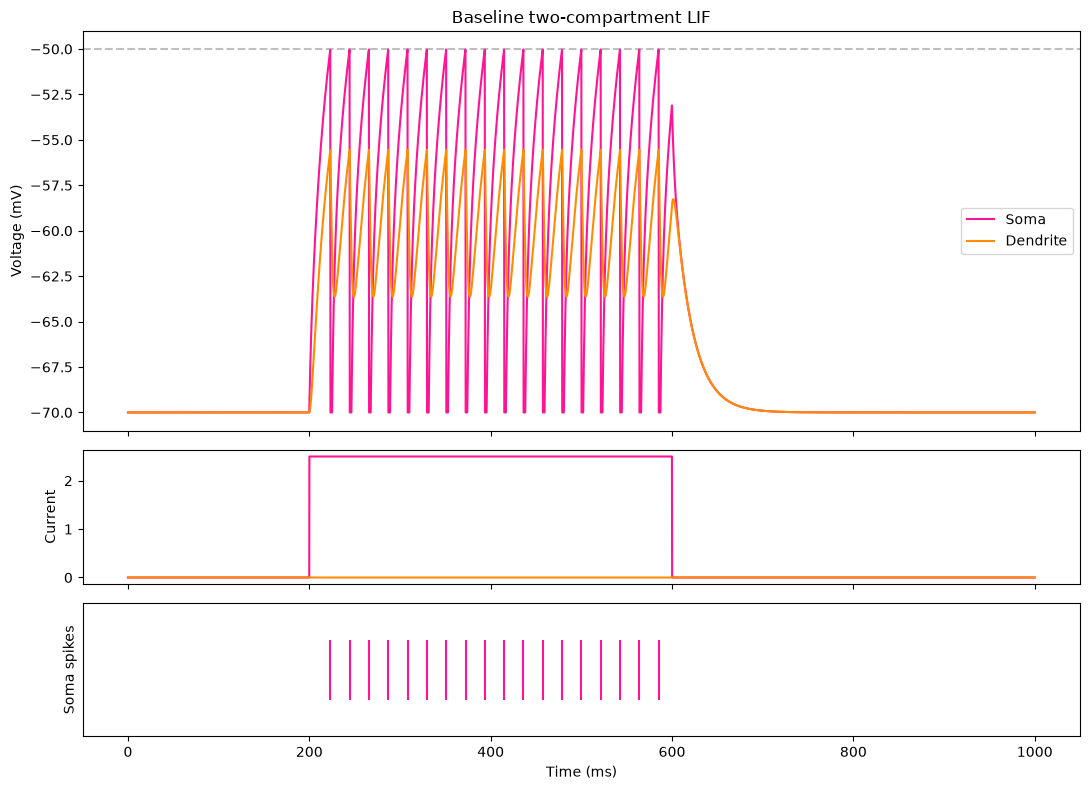

In [10]:
def stimulus(time, baseline=0.0, gain=1.0, location="soma"):
    drive = baseline + 2.5 * gain * ((time >= stim_start) & (time < stim_end))
    if location == "soma":
        return drive, np.zeros_like(time)
    if location == "dendrite":
        return np.full_like(time, baseline), 2.5 * gain * ((time >= stim_start) & (time < stim_end))
    raise ValueError("location must be 'soma' or 'dendrite'")


def simulate_lif(Ibase=0.0, gain=1.0, Vth=-50.0, adaptation_b=0.0,
                 tau_w=150.0, a=0.0, location="soma"):
    Is, Id = stimulus(t, Ibase, gain, location)
    vs = np.zeros(len(t)); vd = np.zeros(len(t)); w = np.zeros(len(t))
    vs[0] = vd[0] = EL
    spikes, last_spike = [], -np.inf
    for i in range(1, len(t)):
        v0, d0 = vs[i-1], vd[i-1]
        I_sd = g_sd * (d0 - v0)
        I_ds = g_ds * (v0 - d0)
        w[i] = w[i-1] + dt * (a * (v0 - EL) - w[i-1]) / tau_w
        vs[i] = v0 + dt * (gLs * (EL - v0) + I_sd + Is[i] - w[i-1]) / Cs
        vd[i] = d0 + dt * (gLd * (EL - d0) + I_ds + Id[i]) / Cd
        if t[i] - last_spike < refractory:
            vs[i] = Vreset
        elif vs[i] >= Vth:
            spikes.append(t[i]); vs[i] = Vreset
            last_spike = t[i]; w[i] += adaptation_b
    return {"vs": vs, "vd": vd, "w": w, "spikes": np.array(spikes), "Is": Is, "Id": Id}

baseline = simulate_lif(Ibase=0.0, gain=1.0, Vth=-50.0)
fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1, 1]})
ax[0].plot(t, baseline["vs"], color=PINK, label="Soma")
ax[0].plot(t, baseline["vd"], color=ORANGE, label="Dendrite")
ax[0].axhline(-50, ls="--", color="gray", alpha=.5)
ax[0].set(ylabel="Voltage (mV)", title="Baseline two-compartment LIF"); ax[0].legend()
ax[1].plot(t, baseline["Is"], color=PINK); ax[1].plot(t, baseline["Id"], color=ORANGE)
ax[1].set(ylabel="Current")
ax[2].eventplot(baseline["spikes"], colors=PINK)
ax[2].set(yticks=[], ylabel="Soma spikes", xlabel="Time (ms)")
plt.tight_layout(); plt.show()

## Frequency response | passive versus dendritic HCN
Frequency sweeps are **subthreshold without spike resets**. We inject a sinusoidal current into either compartment, equilibrate the system without sinusoidal stimulation first, and measure the final cycles. These estimates use peak-to-peak voltage amplitude divided by current amplitude. A low-pass curve alone is not evidence of resonance.

In [ ]:
# HHca2 dendritic HCN kinetics
Gh2, Vh2 = 2.0, -32.9

def h_inf(v):
    return 1.0 / (1.0 + np.exp(np.clip((v + 84.0) / 10.2, -500, 500)))

def tau_h(v):
    return 1.0 / (np.exp(np.clip(-17.9 - 0.116*v, -500, 500))
                  + np.exp(np.clip(-1.84 + 0.09*v, -500, 500))) + 0.1


def impedance_sweep(freqs=np.arange(1, 21), gh=0.0, location="soma", amplitude=0.1,
                    dt_sweep=0.1, settle_ms=2000.0, measure_ms=3000.0):
    # Use current amplitude small enough to analyze linear subthreshold responses.
    total_n = int((settle_ms + measure_ms) / dt_sweep)
    settle_n = int(settle_ms / dt_sweep)
    z_s, z_d = [], []
    for f in freqs:
        vs, vd, h = EL, EL, h_inf(EL)
        soma, dend = [], []
        for i in range(total_n):
            tm = i * dt_sweep
            sine = amplitude * np.sin(2 * np.pi * f * (tm - settle_ms) / 1000) if i >= settle_n else 0.0
            Is = sine if location == "soma" else 0.0
            Id = sine if location == "dendrite" else 0.0
            Ih = gh * h * (vd - Vh2)
            dvs = (gLs*(EL-vs) + g_sd*(vd-vs) + Is) / Cs
            dvd = (gLd*(EL-vd) + g_ds*(vs-vd) + Id - Ih) / Cd
            dh = (h_inf(vd)-h) / tau_h(vd)
            vs += dt_sweep*dvs; vd += dt_sweep*dvd; h += dt_sweep*dh
            if i >= settle_n:
                soma.append(vs); dend.append(vd)
        z_s.append(np.ptp(soma)/(2*amplitude))
        z_d.append(np.ptp(dend)/(2*amplitude))
    return np.asarray(z_s), np.asarray(z_d)

freqs = np.arange(1, 21)
passive_s, passive_d = impedance_sweep(freqs, gh=0.0)
hcn_s, hcn_d = impedance_sweep(freqs, gh=Gh2)

plt.figure(figsize=(10, 5))
plt.plot(freqs, passive_s, "o--", color=PINK, label="Soma: passive")
plt.plot(freqs, hcn_s, "o-", color=PURPLE, label="Soma: HCN")
plt.plot(freqs, passive_d, "o--", color=ORANGE, label="Dendrite: passive")
plt.plot(freqs, hcn_d, "o-", color="orangered", label="Dendrite: HCN")
plt.axvspan(4, 12, color="gray", alpha=0.1, label="Theta band")
plt.xlabel("Input frequency (Hz)"); plt.ylabel("Impedance magnitude (kΩ·cm²)")
plt.title("CA1 reduced model: passive versus dendritic HCN")
plt.legend(); plt.grid(alpha=.2); plt.tight_layout(); plt.show()

## Dendritic stimulation | does input location matter?

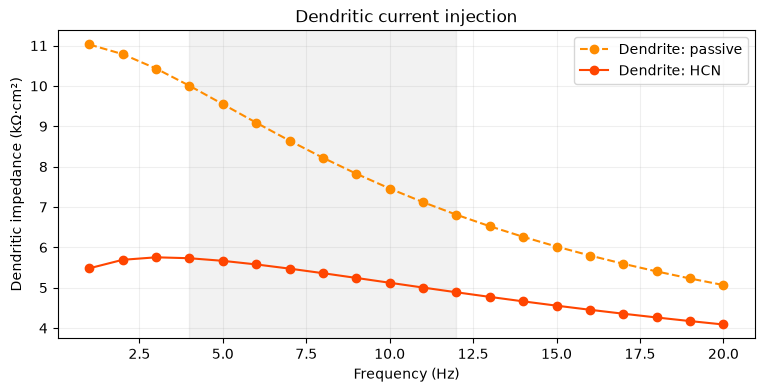

In [ ]:
dend_s_pass, dend_d_pass = impedance_sweep(freqs, gh=0.0, location="dendrite")
dend_s_hcn, dend_d_hcn = impedance_sweep(freqs, gh=Gh2, location="dendrite")
plt.figure(figsize=(9,4))
plt.plot(freqs, dend_d_pass, "o--", color=ORANGE, label="Dendrite: passive")
plt.plot(freqs, dend_d_hcn, "o-", color="orangered", label="Dendrite: HCN")
plt.axvspan(4,12,color="gray",alpha=.1)
plt.xlabel("Frequency (Hz)"); plt.ylabel("Dendritic impedance (kΩ·cm²)")
plt.title("Dendritic current injection")
plt.legend(); plt.grid(alpha=.2); plt.show()

## HHca2 targets | compare against measured reference
From the earlier original-model simulation: 116 spikes in 1000 ms; pre/stim/post rates 55/162.5/100 Hz and CV 0.256/1.739/2.322. Original HHca2 includes baseline currents and conductance-based spike dynamics. These summary statistics are **reference data**, not generated by the reduced model.

Pre   | HHca2:   55.0 Hz / CV 0.256 | LIF:   55.0 Hz / CV 0.000
Stim  | HHca2:  162.5 Hz / CV 1.739 | LIF:  162.5 Hz / CV 0.006
Post  | HHca2:  100.0 Hz / CV 2.322 | LIF:   60.0 Hz / CV 0.000


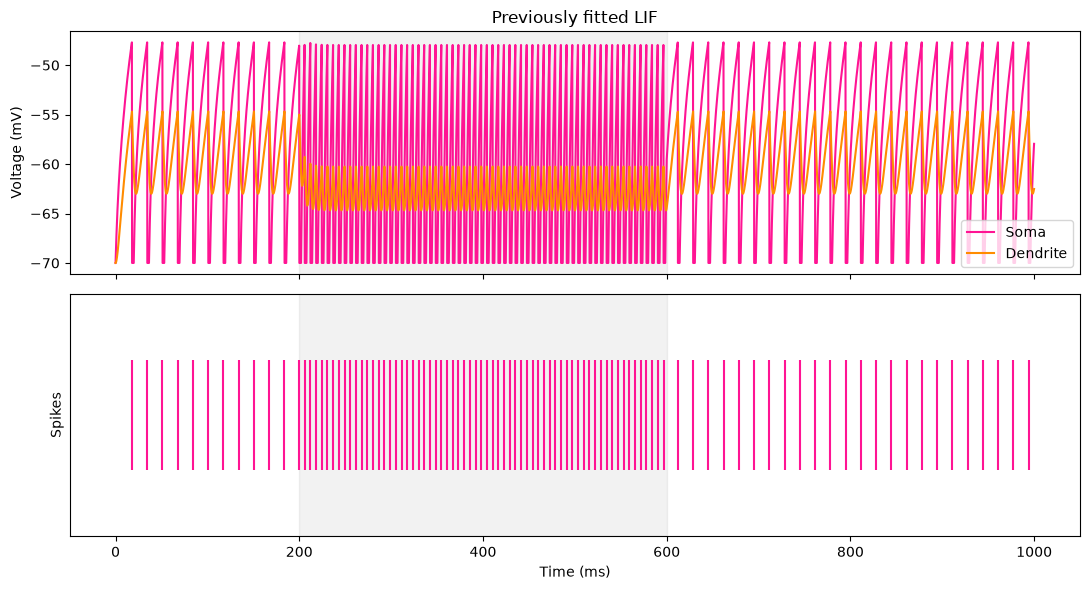

In [ ]:
def spike_metrics(spikes):
    rates, cvs = [], []
    for _, start, end in periods:
        x = spikes[(spikes >= start) & (spikes < end)]
        isi = np.diff(x)
        rates.append(len(x) / ((end-start)/1000))
        cvs.append(np.std(isi)/np.mean(isi) if len(isi)>=2 else np.nan)
    return np.array(rates), np.array(cvs)

fitted = simulate_lif(Ibase_fit, gain_fit, Vth_fit)
fit_rates, fit_cvs = spike_metrics(fitted["spikes"])
for i, (name, _, _) in enumerate(periods):
    print(f"{name:5s} | HHca2: {HH_RATES[i]:6.1f} Hz / CV {HH_CVS[i]:.3f}"
          f" | LIF: {fit_rates[i]:6.1f} Hz / CV {fit_cvs[i]:.3f}")

fig, axes = plt.subplots(2,1,figsize=(11,6),sharex=True)
axes[0].plot(t,fitted["vs"],color=PINK,label="Soma")
axes[0].plot(t,fitted["vd"],color=ORANGE,label="Dendrite")
axes[0].set(ylabel="Voltage (mV)",title="Previously fitted LIF"); axes[0].legend()
axes[1].eventplot(fitted["spikes"],colors=PINK)
axes[1].set(yticks=[],ylabel="Spikes",xlabel="Time (ms)")
for ax in axes: ax.axvspan(200,600,color="gray",alpha=.1)
plt.tight_layout();plt.show()

## Optional | refit pre/stim firing rates
Run this cell **only** if you want to repeat optimization; the notebook works without it. It varies baseline current, stimulus gain, and threshold. The post-stim rate is held out.

In [ ]:
# Uncomment to refit (can take several seconds).
# def loss(params):
#     m = simulate_lif(*params)
#     rates, _ = spike_metrics(m["spikes"])
#     return np.mean(((rates[:2] - HH_RATES[:2]) / HH_RATES[:2])**2)
# result = differential_evolution(loss, [(0.1,5.0),(0.1,5.0),(-60,-35)],
#                                 seed=1, maxiter=30, popsize=8, polish=False)
# print("New fitted Ibase, gain, Vth:", result.x)

## Adaptive LIF | slow spike-triggered current
Add a single recovery variable `w`. Positive `b` adds outward/adapting current after every somatic spike. This **usually suppresses** firing after stimulation; it is a mechanism test, not a guaranteed fix for HHca2 post-stim persistence.

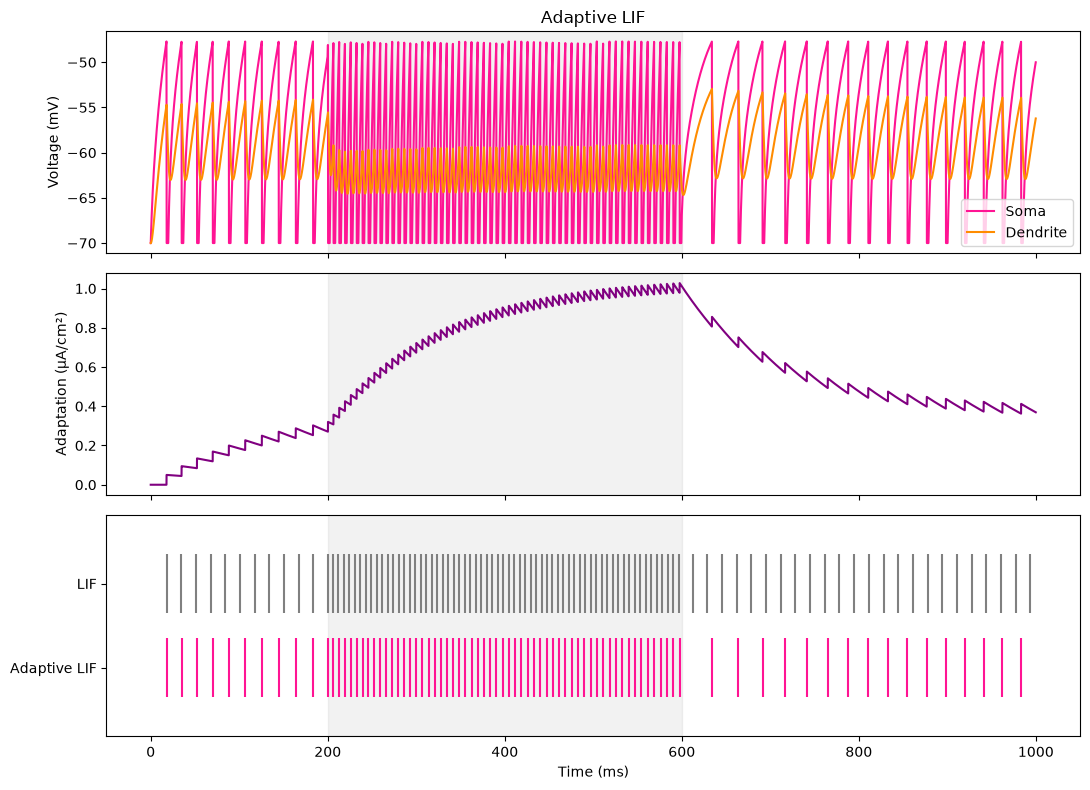

Period |   HHca2 |     LIF |    aLIF (Hz)
Pre   |    55.0 |    55.0 |    50.0
Stim  |   162.5 |   162.5 |   145.0
Post  |   100.0 |    60.0 |    40.0


In [ ]:
tau_w, a, b = 150.0, 0.0, 0.05
adaptive = simulate_lif(Ibase_fit, gain_fit, Vth_fit, tau_w=tau_w, a=a, adaptation_b=b)
adapt_rates, adapt_cvs = spike_metrics(adaptive["spikes"])
fig,axes=plt.subplots(3,1,figsize=(11,8),sharex=True)
axes[0].plot(t,adaptive["vs"],color=PINK,label="Soma")
axes[0].plot(t,adaptive["vd"],color=ORANGE,label="Dendrite")
axes[0].set(ylabel="Voltage (mV)",title="Adaptive LIF"); axes[0].legend()
axes[1].plot(t,adaptive["w"],color=PURPLE)
axes[1].set(ylabel="Adaptation (µA/cm²)")
axes[2].eventplot([fitted["spikes"],adaptive["spikes"]],colors=["gray",PINK],lineoffsets=[1,0],linelengths=.7)
axes[2].set(yticks=[0,1],yticklabels=["Adaptive LIF","LIF"],xlabel="Time (ms)")
for ax in axes: ax.axvspan(200,600,color="gray",alpha=.1)
plt.tight_layout();plt.show()

print(f"{'Period':5s} | {'HHca2':>7s} | {'LIF':>7s} | {'aLIF':>7s} (Hz)")
for i,(name,_,_) in enumerate(periods):
    print(f"{name:5s} | {HH_RATES[i]:7.1f} | {fit_rates[i]:7.1f} | {adapt_rates[i]:7.1f}")

## Explore adaptation strength | one parameter at a time

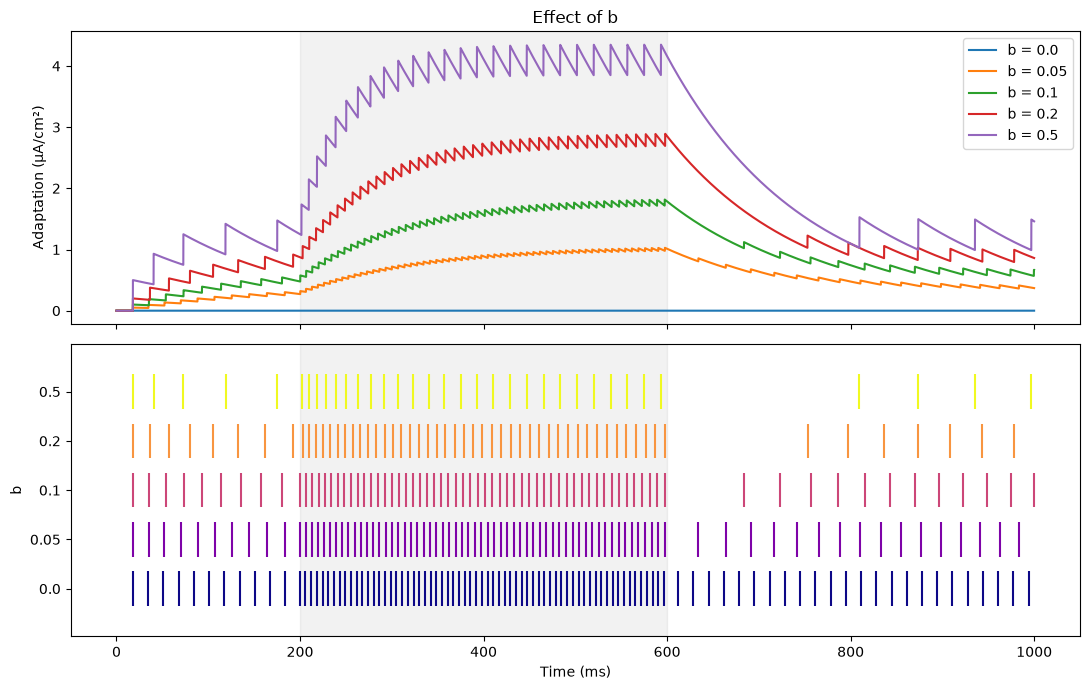

In [ ]:
b_values = [0.0, 0.05, 0.1, 0.2, 0.5]
fig, axes = plt.subplots(2,1,figsize=(11,7),sharex=True)
for j,b_try in enumerate(b_values):
    trial = simulate_lif(Ibase_fit, gain_fit, Vth_fit, tau_w=150, a=0, adaptation_b=b_try)
    axes[0].plot(t,trial["w"],label=f"b = {b_try}")
    axes[1].eventplot(trial["spikes"],lineoffsets=j,linelengths=.7,
                      colors=[plt.cm.plasma(j/(len(b_values)-1))])
axes[0].set(ylabel="Adaptation (µA/cm²)",title="Effect of b"); axes[0].legend()
axes[1].set(yticks=range(len(b_values)),yticklabels=[str(x) for x in b_values],
            ylabel="b",xlabel="Time (ms)")
for ax in axes: ax.axvspan(200,600,color="gray",alpha=.1)
plt.tight_layout();plt.show()

## Interpretation and next fitting priorities
- **Transferred:** capacitance, leak, leak potential, and soma–dendrite coupling are retained as initial nominal values; transfer does not guarantee a correct reduced fit.
- **Fitted:** baseline drive, stimulus gain, and spike threshold match two HHca2 mean firing-rate measurements; they are not biologically unique.
- **Not yet captured:** full HHca2 bursting, elevated post-stimulus firing, spike shape, and resonance/phase locking.
- **Important comparison caveat:** HHca2 also has `Iapp` and `Iapp2`; matching true input drive and reference starting state is needed before attributing differences to mechanisms.
- **Next:** quantify aLIF ISI CV alongside firing rates; then add a *hypothesis-driven* slow inward mechanism if the post-stim discrepancy persists. Reference: [Lowet et al. code](https://github.com/HanLabBU/Lowet-Cell-Reports-2023/blob/main/Cell_reports_scripts/biophysical_modeling/ca1.ipynb).